# 04 — Composition gene by gene

---

Everything so far treated the coding regions as one block. But a genome is not uniform: its genes do different jobs and are under different pressure. The paper does the same split across the eight influenza segments.

RSV has ten genes, in this order along the genome:

`NS1 · NS2 · N · P · M · SH · G · F · M2 · L`

Four are worth knowing:

| Gene | Role |
|---|---|
| **NS1, NS2** | interferon antagonists — they switch off the cell's antiviral alarm |
| **G** | attachment protein, surface-exposed, the most variable gene |
| **F** | fusion protein, target of nirsevimab and the recent vaccines |
| **L** | polymerase, about 43% of the genome, so it dominates any genome-wide average |

---

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; the R scripts expect to run from here
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
PAL = {"A": "#2C7FB8", "B": "#C62824"}    # same colours as the R figures

def run_r(script="R/figures.R"):
    """Run the R figure script from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))


## 4.1  Composition of each gene

In [2]:
g = pd.read_csv("../data/processed/rsv_gene_features.tsv", sep="\t")
GENES = ["NS1","NS2","N","P","M","SH","G","F","M2","L"]
per_gene = g[g.gene != "GENOME"]
tab = (per_gene.groupby(["Subtype", "gene"])
       .agg(n=("gc_content","size"), length=("valid_len","median"),
            gc=("gc_content","mean"), gc3=("gc3","mean"),
            oe_CG=("oe_CG","mean"), oe_GG=("oe_GG","mean")).reset_index())
tab["gene"] = pd.Categorical(tab["gene"], GENES, ordered=True)
tab.sort_values(["Subtype","gene"]).round(4)

,Subtype,gene,n,length,gc,gc3,oe_CG,oe_GG
6,A,NS1,15458,420.0,0.3047,0.2720,0.0161,1.0860
7,A,NS2,15458,375.0,0.3422,0.3626,0.0715,1.2784
5,A,N,15458,1176.0,0.3696,0.2917,0.1753,1.0956
8,A,P,15458,726.0,0.3570,0.2755,0.1561,0.7883
3,A,M,15458,771.0,0.3661,0.3234,0.2034,0.8535
9,A,SH,15458,195.0,0.3188,0.3896,0.4039,1.0035
1,A,G,15458,969.0,0.4300,0.4519,0.3264,1.6279
0,A,F,15458,1725.0,0.3525,0.3087,0.2188,0.9450
4,A,M2,15458,585.0,0.3637,0.3508,0.4061,0.7686
2,A,L,15458,6498.0,0.3080,0.2550,0.2680,1.0710


### Patterns

**The G gene stands out** — the highest GC content of any gene, well above the genome-wide figure. It is the most variable gene and the most exposed to antibodies, so it is the natural region to examine on its own.

**CpG suppression is uneven along the genome**, and in RSV-A the two interferon antagonist genes sit far below everything else.

In [3]:
run_r()

figures written to results/figures/
fig5 written


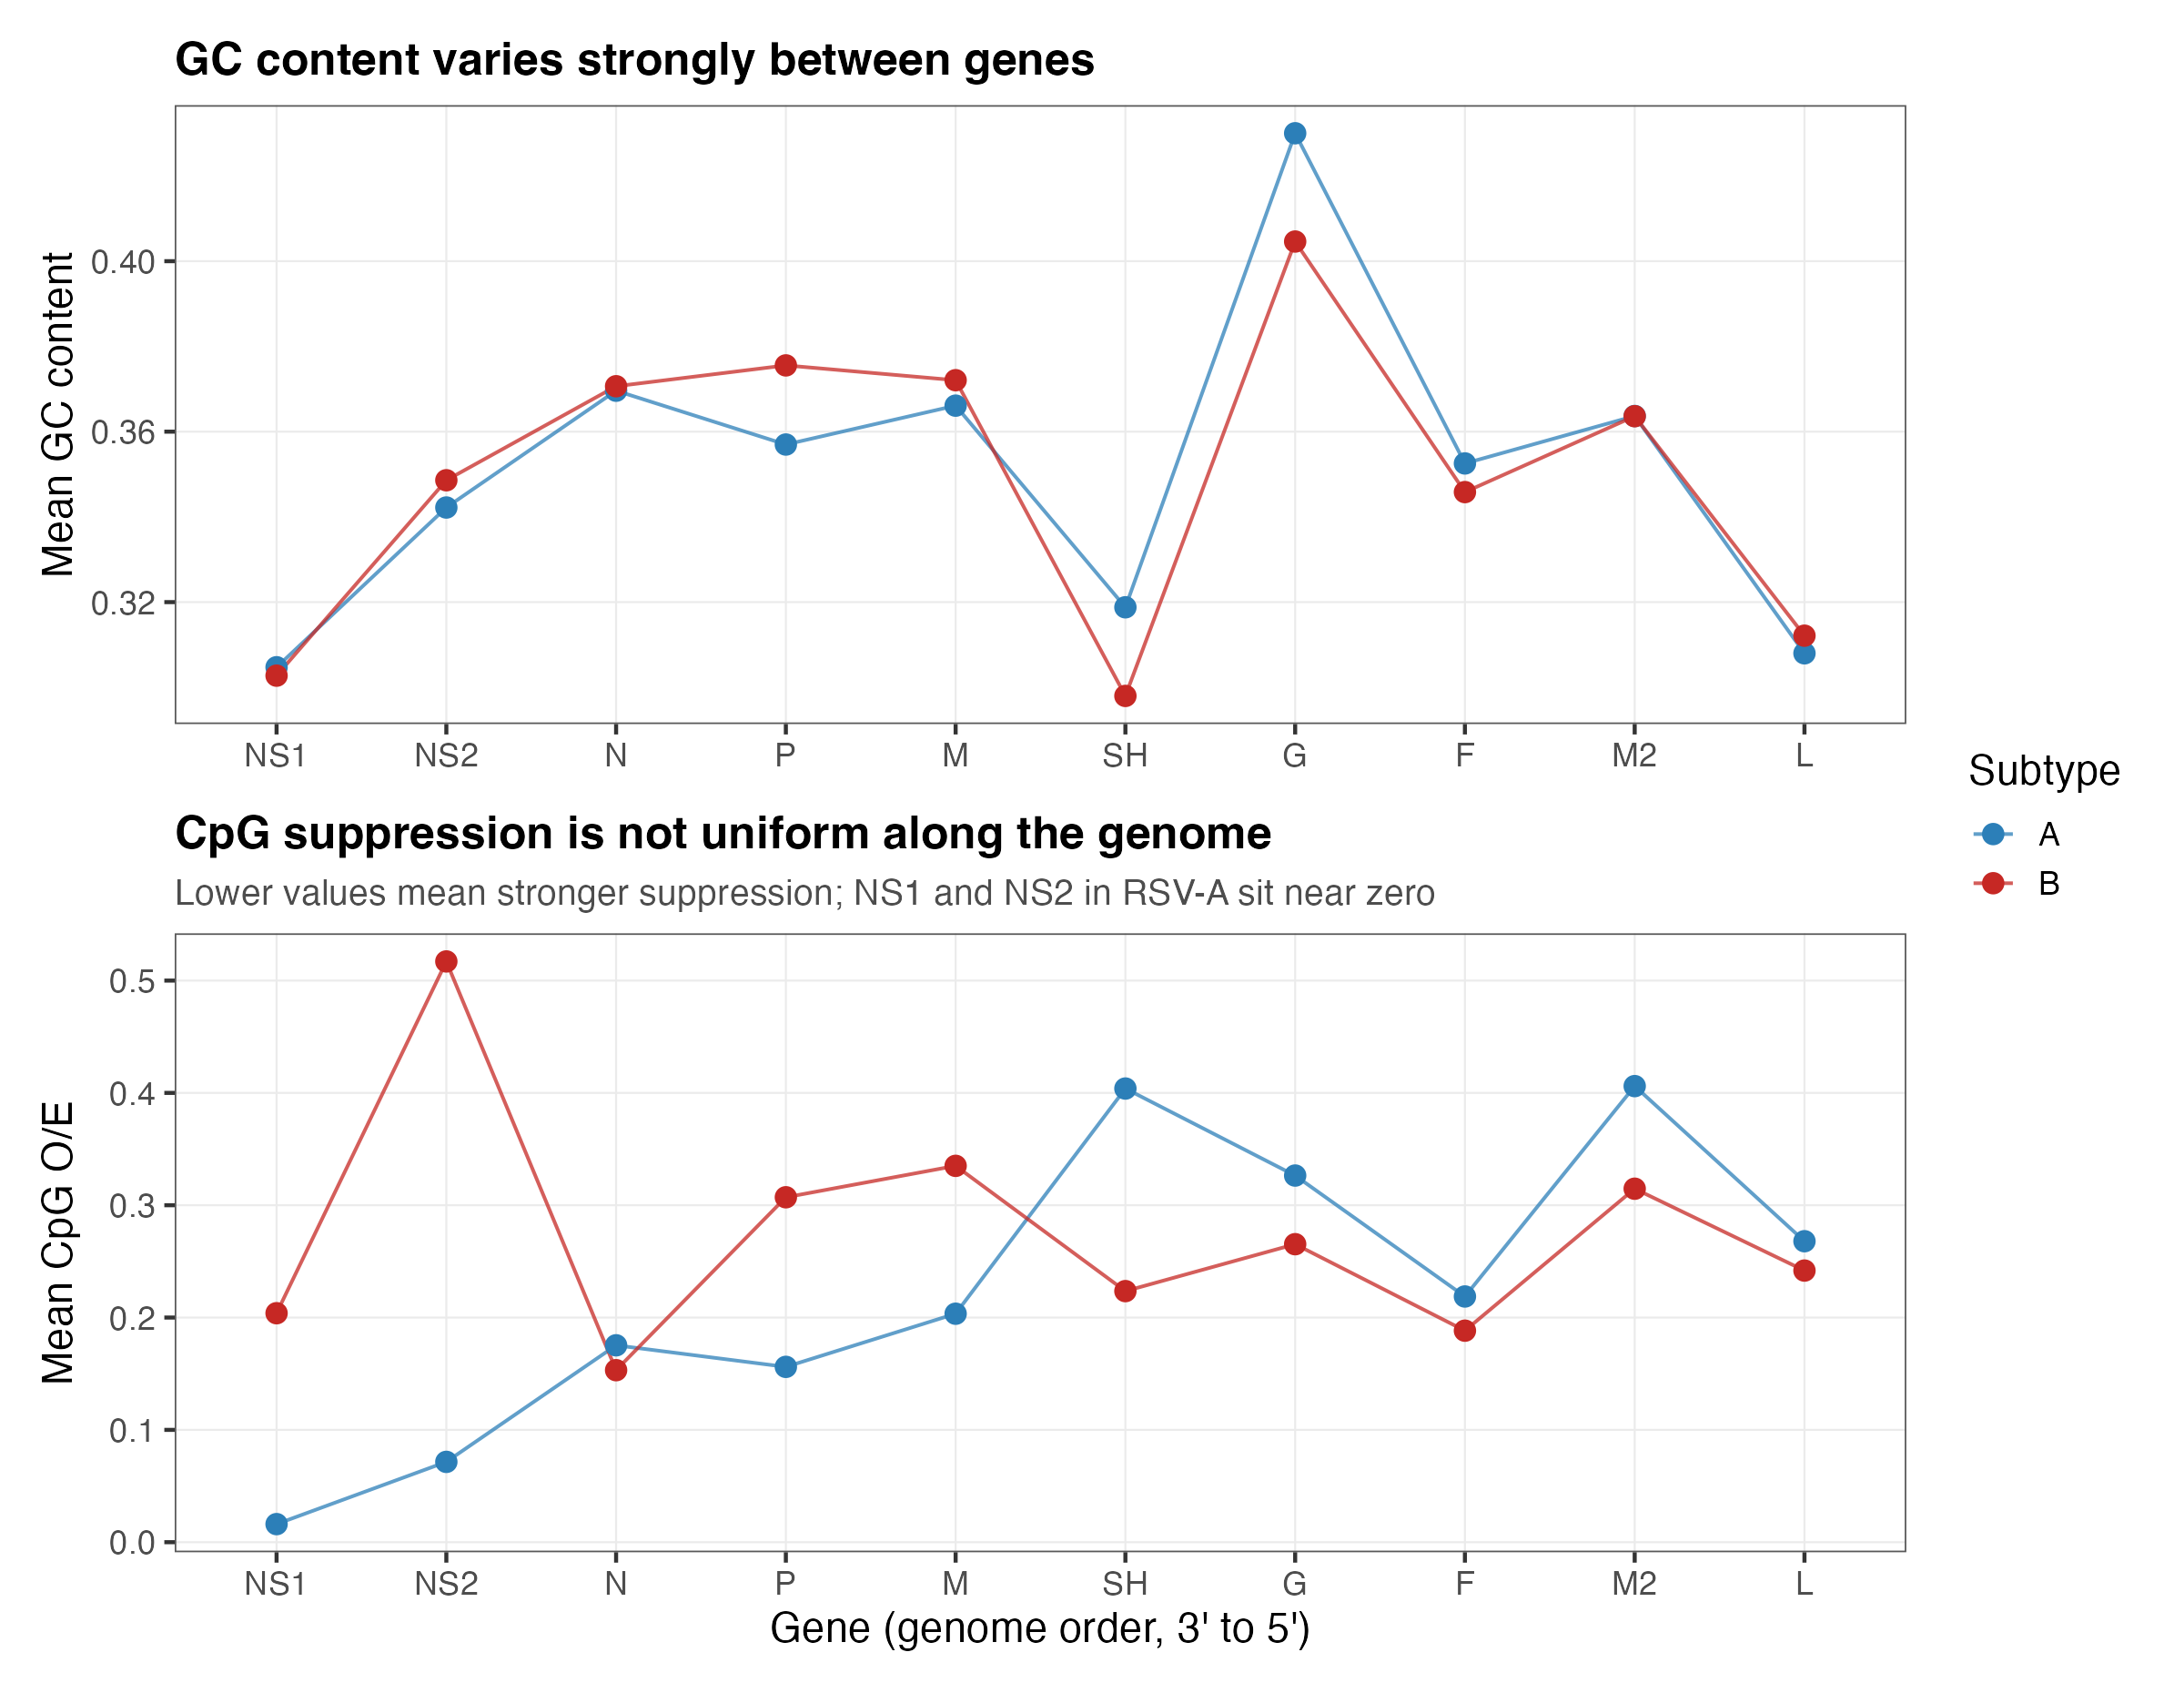

In [4]:
show("fig5_gene_composition.png")

## 4.2  The NS1 and NS2 contrast

Taking the two interferon antagonist genes directly, with two ordinary genes for comparison.

In [5]:
sel = per_gene[per_gene.gene.isin(["NS1","NS2","N","L"])]
cmp = (sel.groupby(["gene","Subtype"])
       .apply(lambda s: pd.Series({
           "CpG per gene": (s.freq_CG * s.valid_len).mean(),
           "% genomes with zero CpG": (s.freq_CG == 0).mean() * 100,
           "GC content": s.gc_content.mean()}), include_groups=False)
       .round(3))
cmp

CpG per gene  % genomes with zero CpG  GC content
gene Subtype                                                   
L    A              41.211                    0.000       0.308
     B              38.235                    0.000       0.312
N    A               6.862                    0.000       0.370
     B               6.088                    0.000       0.371
NS1  A               0.159                   84.778       0.305
     B               1.943                    0.506       0.303
NS2  A               0.758                   34.189       0.342
     B               5.641                    0.000       0.349

**Read the NS1 rows.** In RSV-A the gene carries almost no CpG at all, and in most RSV-A genomes there is none anywhere in it. RSV-B's copy of the same gene carries several. GC content is nearly identical between the two, so this is not a side effect of base composition — it is specific to the CpG pair.

N and L, shown for comparison, behave the same way in both subtypes, so this is not a general difference between A and B.

This is an observation about sequence, not a demonstrated mechanism. Testing it would require laboratory work.

## 4.3  Which genes carry the time trend?

The same within-lineage regression from notebook 03, run on each gene separately. The equivalent of the paper's Figure 2b.

In [6]:
bg = pd.read_csv("../results/slopes_by_gene.tsv", sep="\t")
bg = bg[bg.feature == "oe_CG"]
piv = bg.pivot_table(index="gene", columns=["Subtype","lineage_grp"], values="slope")
piv = piv.reindex(GENES)
piv.round(5)

Subtype            A                                                     B                           
lineage_grp      A.D    A.D.1    A.D.2    A.D.3    A.D.4    A.D.5      B.D    B.D.1    B.D.4    B.D.E
gene                                                                                                 
NS1          0.00204  0.00042 -0.00130  0.00414 -0.00045  0.00244 -0.00102 -0.00057 -0.00040  0.00603
NS2          0.00185  0.00025  0.00100  0.00135 -0.00004  0.00606  0.00118  0.00627  0.00337 -0.00757
N           -0.00045  0.00235  0.00050  0.00157  0.00183 -0.00064  0.00146  0.00429  0.00039  0.00060
P           -0.00107  0.00132  0.00126  0.00122  0.00426 -0.00178 -0.00354 -0.00129 -0.00121 -0.00181
M            0.00011  0.00249  0.00139 -0.00055  0.00012  0.00039 -0.00301 -0.00039 -0.00062 -0.00471
SH           0.00091 -0.00792 -0.00024 -0.00008 -0.00951 -0.02484  0.00156 -0.00184  0.01722 -0.00100
G           -0.00064  0.00305 -0.00223 -0.00568  0.00082 -0.00188  0.00242  0.00296  0.00030  0.00103
F           -0.00130 -0.00070 -0.00152  0.00105 -0.00066 -0.00090  0.00007  0.00041  0.00275  0.00504
M2           0.00196 -0.00338 -0.00125 -0.00272  0.00302 -0.00200  0.00284 -0.00028  0.00003  0.00314
L            0.00022  0.00040  0.00086 -0.00141 -0.00019 -0.00128 -0.00021  0.00104 -0.00084  0.00047

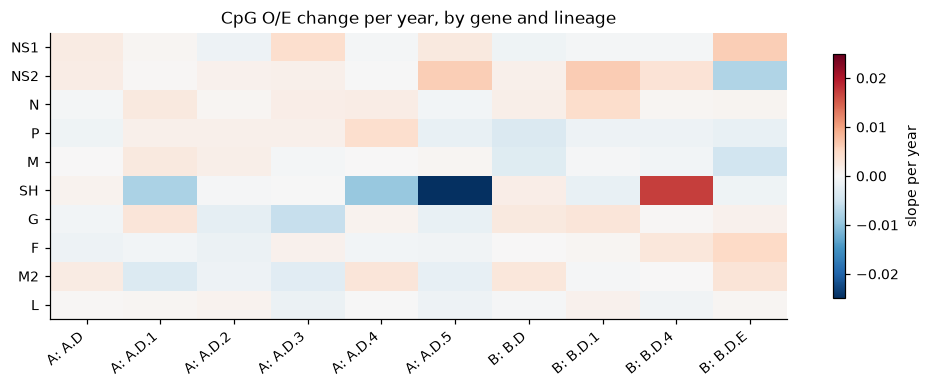

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
vals = piv.values.astype(float)
lim = np.nanmax(np.abs(vals))
im = ax.imshow(vals, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
ax.set_xticks(range(piv.shape[1]))
ax.set_xticklabels([f"{a}: {b}" for a, b in piv.columns], rotation=40, ha="right")
ax.set_title("CpG O/E change per year, by gene and lineage")
fig.colorbar(im, ax=ax, shrink=.85, label="slope per year")
plt.tight_layout(); plt.show()

Red means CpG O/E rising in that gene and lineage, blue means falling. Reading across a row shows whether a gene behaves consistently across lineages.